# ⚽ Real-World Data Challenge
## FIFA 19 — What Makes a Top Football Player?
### ⏱️ Time Allowed: 2 – 2.5 Hours &nbsp;|&nbsp; Open: Syntax Sheet &nbsp;|&nbsp; Closed: Internet

---

> **The Story:**
> EA Sports collected detailed data on **18,000+ real professional footballers** for FIFA 19.
> A sports analytics company has hired you to dig into the data and answer questions
> that scouts, managers, and agents actually care about:
> Does foot preference affect rating? Do forwards outperform defenders?
> What best predicts a player's market value?
>
> Your job: **explore, test, visualise, and brief the scouting team.**

---

### 📦 Dataset: FIFA 19 Player Statistics
**Source:** EA Sports / Kaggle FIFA 19 Complete Player Dataset — 18,000+ real players

| Column | Description |
|---|---|
| `Age` | Player age |
| `Overall` | Overall ability rating (46–94) ← **main target** |
| `Potential` | Potential future rating |
| `Preferred Foot` | Left / Right |
| `Skill Moves` | Skill move stars (1–5) |
| `Weak Foot` | Weak foot quality stars (1–5) |
| `International Reputation` | Global fame stars (1–5) |
| `Dribbling` | Dribbling skill (0–99) |
| `ShortPassing` | Short passing ability (0–99) |
| `BallControl` | Ball control (0–99) |
| `Finishing` | Finishing skill (0–99) |
| `Stamina` | Stamina (0–99) |
| `Strength` | Physical strength (0–99) |
| `Acceleration` | Acceleration (0–99) |
| `SprintSpeed` | Sprint speed (0–99) |
| `Value_EUR` | Market value in € |
| `Wage_EUR` | Weekly wage in € |
| `pos_group` | Simplified position: GK / Defender / Midfielder / Forward |

---

### 🧭 Challenge Map

| Task | Topic | Est. Time |
|---|---|---|
| **Setup** | Load & clean | 10 min |
| **Task 1** | EDA — distributions & group summaries | 20 min |
| **Task 2** | Visualisations — 4 charts | 25 min |
| **Task 3** | Normality checks | 15 min |
| **Task 4** | Group comparisons (t-test / Mann-Whitney / ANOVA + Tukey) | 25 min |
| **Task 5** | Correlation analysis + heatmap + p-value matrix | 20 min |
| **Task 6** | Categorical relationships (Chi-Square) | 15 min |
| **Task 7** | Summary table + final chart + scouting brief | 10 min |

---
```
p ≤ 0.05  →  Reject H₀   (something real is happening)
p > 0.05  →  Keep H₀     (could be random chance)
```


### ✅ Completed Solution Notebook
All starter cells have been completed. Run the notebook **top-to-bottom in Google Colab**.  
Statistical test choices are made programmatically from the data, and the final summary/brief uses the computed results rather than hard-coded values.


---
## ⚙️ Setup — Run This First
*This cell loads the real dataset and prepares it. Do not change it.*

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# ── Load raw FIFA 19 data ────────────────────────────────────────────────────
url = ("https://raw.githubusercontent.com/amanthedorkknight/"
       "fifa18-all-player-statistics/master/2019/data.csv")
raw = pd.read_csv(url)

# ── Clean Value and Wage (convert "€110.5M" → 110500000) ────────────────────
def parse_money(s):
    if pd.isna(s): return np.nan
    s = str(s).replace('€', '').strip()
    if 'M' in s: return float(s.replace('M', '')) * 1_000_000
    if 'K' in s: return float(s.replace('K', '')) * 1_000
    try:    return float(s)
    except: return np.nan

raw['Value_EUR'] = raw['Value'].apply(parse_money)
raw['Wage_EUR']  = raw['Wage'].apply(parse_money)

# ── Simplify position into 4 groups ─────────────────────────────────────────
def pos_group(p):
    if pd.isna(p): return None
    p = str(p).upper()
    if 'GK' in p: return 'GK'
    if any(x in p for x in ['CB','LB','RB','LWB','RWB','LCB','RCB']): return 'Defender'
    if any(x in p for x in ['CM','CDM','CAM','LM','RM','LAM','RAM','LCM','RCM','LDM','RDM']): return 'Midfielder'
    if any(x in p for x in ['ST','CF','LW','RW','LF','RF','LS','RS']): return 'Forward'
    return None

raw['pos_group'] = raw['Position'].apply(pos_group)

# ── Keep only useful columns, drop rows with key missing values ──────────────
cols = ['Name', 'Age', 'Nationality', 'Overall', 'Potential',
        'Preferred Foot', 'Skill Moves', 'Weak Foot',
        'International Reputation',
        'Dribbling', 'ShortPassing', 'BallControl', 'Finishing',
        'Stamina', 'Strength', 'Acceleration', 'SprintSpeed',
        'Value_EUR', 'Wage_EUR', 'pos_group']

df = (raw[cols]
      .dropna(subset=['Overall', 'Age', 'Preferred Foot', 'pos_group'])
      .query("pos_group in ['GK', 'Defender', 'Midfielder', 'Forward']")
      .reset_index(drop=True))

print("✅ Dataset ready!")
print(f"   Players : {len(df):,}")
print(f"   Columns : {df.shape[1]}")
print()
print(df['pos_group'].value_counts().to_string())
df.head()


✅ Dataset ready!
   Players : 18,147
   Columns : 20

pos_group
Midfielder    6838
Defender      5866
Forward       3418
GK            2025


,Name,Age,Nationality,Overall,Potential,Preferred Foot,Skill Moves,Weak Foot,International Reputation,Dribbling,ShortPassing,BallControl,Finishing,Stamina,Strength,Acceleration,SprintSpeed,Value_EUR,Wage_EUR,pos_group
0,L. Messi,31,Argentina,94,94,Left,4.0,4.0,5.0,97.0,90.0,96.0,95.0,72.0,59.0,91.0,86.0,110500000.0,565000.0,Forward
1,Cristiano Ronaldo,33,Portugal,94,94,Right,5.0,4.0,5.0,88.0,81.0,94.0,94.0,88.0,79.0,89.0,91.0,77000000.0,405000.0,Forward
2,Neymar Jr,26,Brazil,92,93,Right,5.0,5.0,5.0,96.0,84.0,95.0,87.0,81.0,49.0,94.0,90.0,118500000.0,290000.0,Forward
3,De Gea,27,Spain,91,93,Right,1.0,3.0,4.0,18.0,50.0,42.0,13.0,43.0,64.0,57.0,58.0,72000000.0,260000.0,GK
4,K. De Bruyne,27,Belgium,91,92,Right,4.0,5.0,4.0,86.0,92.0,91.0,82.0,90.0,75.0,78.0,76.0,102000000.0,355000.0,Midfielder


---
## 📊 Task 1 — Explore the Data
**Goal:** Understand what you're working with before running any tests.

---

### 1a. Basic Inspection

Write code to answer:
1. How many players and columns are in `df`?
2. Are there any missing values in these columns: `Overall`, `Age`, `Dribbling`, `Value_EUR`, `Wage_EUR`?
3. What is the average, minimum, and maximum **Overall** rating?
4. How many players are in each **position group** (`pos_group`)?

💡 **Hints:** `.shape` · `.isnull().sum()` · `.describe()` · `.value_counts()`


In [ ]:
# 1a — Basic Inspection
print("1) Dataset shape")
print(f"   Players: {df.shape[0]:,}")
print(f"   Columns: {df.shape[1]}")
print()

check_cols = ['Overall', 'Age', 'Dribbling', 'Value_EUR', 'Wage_EUR']
missing_1a = df[check_cols].isnull().sum()
print("2) Missing values")
print(missing_1a.to_string())
print()

overall_stats = df['Overall'].agg(['mean', 'min', 'max'])
print("3) Overall rating")
print(f"   Mean: {overall_stats['mean']:.2f}")
print(f"   Min : {overall_stats['min']:.0f}")
print(f"   Max : {overall_stats['max']:.0f}")
print()

position_counts = df['pos_group'].value_counts().reindex(
    ['GK', 'Defender', 'Midfielder', 'Forward']
)
print("4) Position group counts")
print(position_counts.to_string())

1) Dataset shape
   Players: 18,147
   Columns: 20

2) Missing values
Overall      0
Age          0
Dribbling    0
Value_EUR    0
Wage_EUR     0

3) Overall rating
   Mean: 66.25
   Min : 46
   Max : 94

4) Position group counts
pos_group
GK            2025
Defender      5866
Midfielder    6838
Forward       3418


---
### 1b. Group Summaries

Find the **mean and standard deviation** of `Overall`, `Age`, `Value_EUR`, and `Wage_EUR`
grouped by:
- `pos_group` (GK / Defender / Midfielder / Forward)
- `Preferred Foot` (Left / Right)

💡 **Hint:** `df.groupby('col')[['Overall','Age']].agg(['mean','std']).round(2)`


In [ ]:
# 1b — Group summaries by position
summary_by_position = (
    df.groupby('pos_group')[['Overall', 'Age', 'Value_EUR', 'Wage_EUR']]
      .agg(['mean', 'std'])
      .round(2)
      .reindex(['GK', 'Defender', 'Midfielder', 'Forward'])
)
summary_by_position

Overall          Age         Value_EUR              Wage_EUR  \
              mean   std   mean   std        mean         std      mean   
pos_group                                                                 
GK           64.60  7.60  26.04  5.47  1585814.81  4562890.61   6803.95   
Defender     66.40  6.46  25.47  4.52  1975138.08  4106420.51   9146.10   
Midfielder   66.55  6.96  24.78  4.51  2760639.08  5890612.59  10180.61   
Forward      66.40  7.02  24.66  4.61  2984155.94  7395815.54  11718.26   

                      
                 std  
pos_group             
GK          16719.63  
Defender    18970.31  
Midfielder  21932.88  
Forward     28662.56

In [ ]:
# Group summaries by Preferred Foot
summary_by_foot = (
    df.groupby('Preferred Foot')[['Overall', 'Age', 'Value_EUR', 'Wage_EUR']]
      .agg(['mean', 'std'])
      .round(2)
)
summary_by_foot

Overall          Age         Value_EUR              Wage_EUR  \
                  mean   std   mean   std        mean         std      mean   
Preferred Foot                                                                
Left             66.80  6.56  25.10  4.52  2588727.73  5956115.19  10353.29   
Right            66.09  7.01  25.13  4.71  2366090.90  5490850.79   9579.57   

                          
                     std  
Preferred Foot            
Left            23656.32  
Right           21512.73

---
### 1c. Written Observations ✍️

Fill in the blanks after running your code:

```
1. The dataset has _____ players and _____ columns.

2. Missing values found in:
   Overall _____  Age _____  Dribbling _____
   Value_EUR _____  Wage_EUR _____

3. Overall rating → Mean: _____  Min: _____  Max: _____

4. Position group counts:
   GK: _____   Defender: _____   Midfielder: _____   Forward: _____

5. Which position group has the highest average Overall? _____________

6. Do left-footed or right-footed players have a higher average Overall?
   _______________  by _____  rating points.
```


In [ ]:
# 1c — Completed written observations (calculated from the data)
highest_pos = df.groupby('pos_group')['Overall'].mean().idxmax()
foot_means = df.groupby('Preferred Foot')['Overall'].mean()
higher_foot = foot_means.idxmax()
foot_difference = abs(foot_means['Left'] - foot_means['Right'])

print(f"1. The dataset has {len(df):,} players and {df.shape[1]} columns.\n")
print("2. Missing values found in:")
for col in ['Overall', 'Age', 'Dribbling', 'Value_EUR', 'Wage_EUR']:
    print(f"   {col}: {df[col].isnull().sum()}")
print()
print(f"3. Overall rating → Mean: {df['Overall'].mean():.2f}  "
      f"Min: {df['Overall'].min():.0f}  Max: {df['Overall'].max():.0f}\n")
print("4. Position group counts:")
for pos in ['GK', 'Defender', 'Midfielder', 'Forward']:
    print(f"   {pos}: {(df['pos_group'] == pos).sum():,}")
print()
print(f"5. Position group with the highest average Overall: {highest_pos}")
print(f"6. {higher_foot}-footed players have the higher average Overall by "
      f"{foot_difference:.2f} rating points.")

1. The dataset has 18,147 players and 20 columns.

2. Missing values found in:
   Overall: 0
   Age: 0
   Dribbling: 0
   Value_EUR: 0
   Wage_EUR: 0

3. Overall rating → Mean: 66.25  Min: 46  Max: 94

4. Position group counts:
   GK: 2,025
   Defender: 5,866
   Midfielder: 6,838
   Forward: 3,418

5. Position group with the highest average Overall: Midfielder
6. Left-footed players have the higher average Overall by 0.72 rating points.


---
## 🎨 Task 2 — Visualisations
**Goal:** See the data. Statistics without charts are blind.

---

### 2a. The Big Four — 2×2 Subplot Grid

Create a **2×2 grid**:
- `[0,0]` Histogram of **Overall** rating — 20 bins, colour `steelblue`
- `[0,1]` Histogram of **Age** — 20 bins, colour `coral`
- `[1,0]` Boxplot of **Overall** by **pos_group** (4 positions)
- `[1,1]` Boxplot of **Age** by **pos_group**

Every subplot needs **title, xlabel, ylabel**. Write one `# observation:` comment per plot.

💡 **Hints:**  
`ax.hist(df['Overall'], bins=20, color='steelblue', edgecolor='white')`  
`df.boxplot(column='Overall', by='pos_group', ax=axes[1,0])`  
`plt.suptitle(...)` · `plt.tight_layout()`


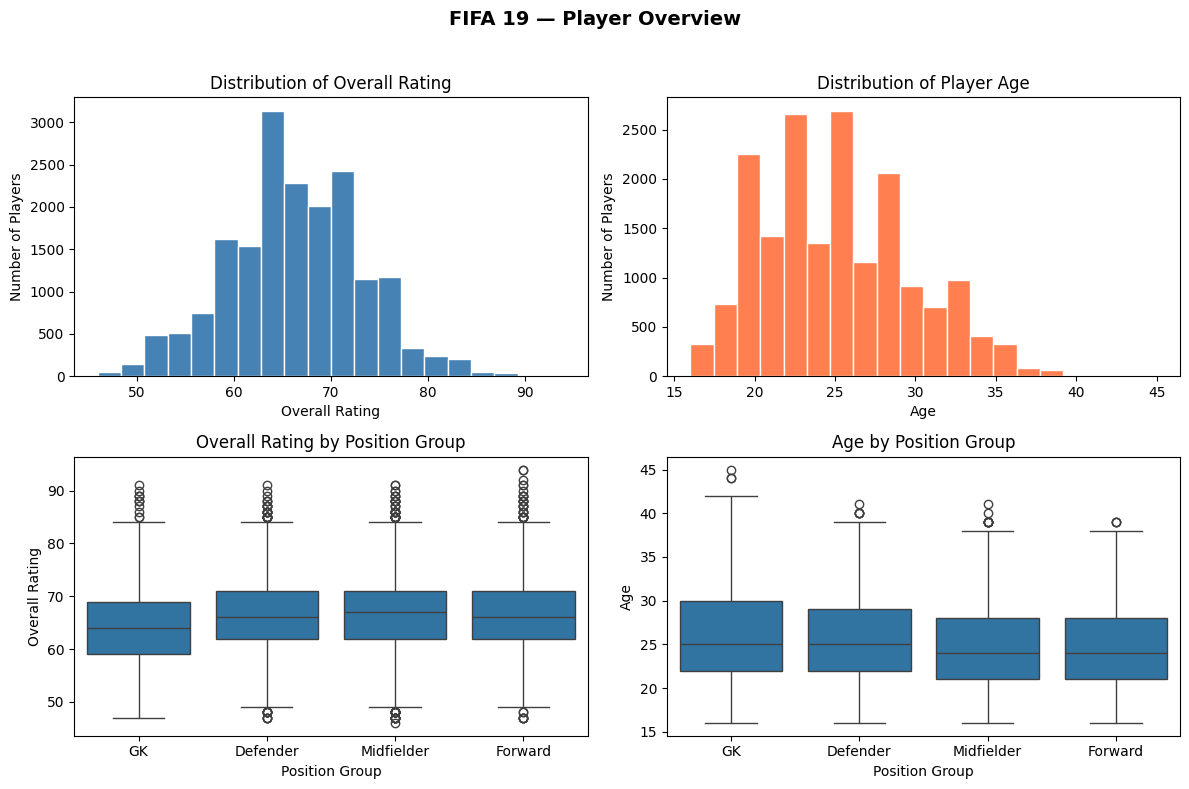

In [ ]:
# 2a — 2×2 Subplot Grid
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# [0,0] Histogram of Overall
axes[0, 0].hist(df['Overall'].dropna(), bins=20, color='steelblue', edgecolor='white')
axes[0, 0].set_title('Distribution of Overall Rating')
axes[0, 0].set_xlabel('Overall Rating')
axes[0, 0].set_ylabel('Number of Players')
# observation: Most players cluster around the middle ratings, with relatively few at the extremes.

# [0,1] Histogram of Age
axes[0, 1].hist(df['Age'].dropna(), bins=20, color='coral', edgecolor='white')
axes[0, 1].set_title('Distribution of Player Age')
axes[0, 1].set_xlabel('Age')
axes[0, 1].set_ylabel('Number of Players')
# observation: The dataset contains many players in their early-to-mid twenties and fewer older players.

# [1,0] Boxplot: Overall by pos_group
sns.boxplot(data=df, x='pos_group', y='Overall',
            order=['GK', 'Defender', 'Midfielder', 'Forward'], ax=axes[1, 0])
axes[1, 0].set_title('Overall Rating by Position Group')
axes[1, 0].set_xlabel('Position Group')
axes[1, 0].set_ylabel('Overall Rating')
# observation: The position groups overlap strongly, although their medians are not identical.

# [1,1] Boxplot: Age by pos_group
sns.boxplot(data=df, x='pos_group', y='Age',
            order=['GK', 'Defender', 'Midfielder', 'Forward'], ax=axes[1, 1])
axes[1, 1].set_title('Age by Position Group')
axes[1, 1].set_xlabel('Position Group')
axes[1, 1].set_ylabel('Age')
# observation: Age distributions differ modestly across positions, with substantial overlap.

plt.suptitle('FIFA 19 — Player Overview', fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

---
### 2b. Scatter Plot — Age vs Overall Rating

Create a scatter plot of **Age** (x) vs **Overall** (y).
- Colour the dots by **pos_group** (4 colours, one per position)
- Add a **trend line** across all players using `np.polyfit`
- Proper title, xlabel, ylabel, legend

💡 **Hints:**  
`sns.scatterplot(data=df, x='Age', y='Overall', hue='pos_group', alpha=0.4, ax=ax)`  
`m, b = np.polyfit(df['Age'], df['Overall'], 1)`  
`x_line = np.linspace(df['Age'].min(), df['Age'].max(), 100)`  
`ax.plot(x_line, m*x_line + b, color='black', linewidth=2, linestyle='--')`

> After plotting — does the trend line go up or down? What does that mean for a player's career?


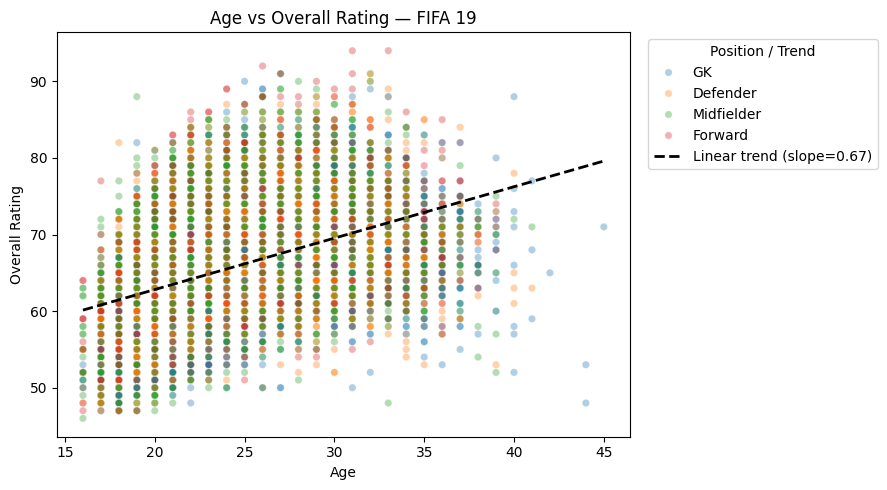

Trend direction: upward (slope = 0.671).
Interpretation: in this cross-sectional dataset, older players tend to have higher current Overall ratings on average. This is an association, not proof that rating always rises throughout an individual player's career.


In [ ]:
# 2b — Scatter: Age vs Overall
fig, ax = plt.subplots(figsize=(9, 5))

# Scatter coloured by pos_group
sns.scatterplot(data=df, x='Age', y='Overall', hue='pos_group',
                hue_order=['GK', 'Defender', 'Midfielder', 'Forward'],
                alpha=0.35, s=28, ax=ax)

# Trend line across all players
clean_age_overall = df[['Age', 'Overall']].dropna()
m, b = np.polyfit(clean_age_overall['Age'], clean_age_overall['Overall'], 1)
x_line = np.linspace(clean_age_overall['Age'].min(), clean_age_overall['Age'].max(), 100)
ax.plot(x_line, m * x_line + b, color='black', linewidth=2, linestyle='--',
        label=f'Linear trend (slope={m:.2f})')

ax.set_title('Age vs Overall Rating — FIFA 19')
ax.set_xlabel('Age')
ax.set_ylabel('Overall Rating')
ax.legend(title='Position / Trend', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

trend_direction = 'upward' if m > 0 else 'downward' if m < 0 else 'flat'
print(f"Trend direction: {trend_direction} (slope = {m:.3f}).")
if m > 0:
    print("Interpretation: in this cross-sectional dataset, older players tend to have higher current Overall ratings on average. "
          "This is an association, not proof that rating always rises throughout an individual player's career.")
elif m < 0:
    print("Interpretation: older players tend to have lower current Overall ratings on average in this dataset.")
else:
    print("Interpretation: age has almost no linear association with current Overall rating in this dataset.")

---
### 2c. Bar Chart — Average Overall by Position (with Error Bars)

Create a **bar chart** showing the average Overall for each `pos_group`.
- Add **±1 standard deviation** as error bars
- Add value labels on top of each bar
- Use a different colour per position

💡 **Hints:**
```python
grouped = df.groupby('pos_group')['Overall'].agg(['mean','std']).reset_index()
ax.bar(grouped['pos_group'], grouped['mean'],
       yerr=grouped['std'], capsize=5, color=[...], edgecolor='black')
for bar, m in zip(bars, grouped['mean']):
    ax.text(bar.get_x() + bar.get_width()/2, m + 1, f'{m:.1f}', ha='center')
```


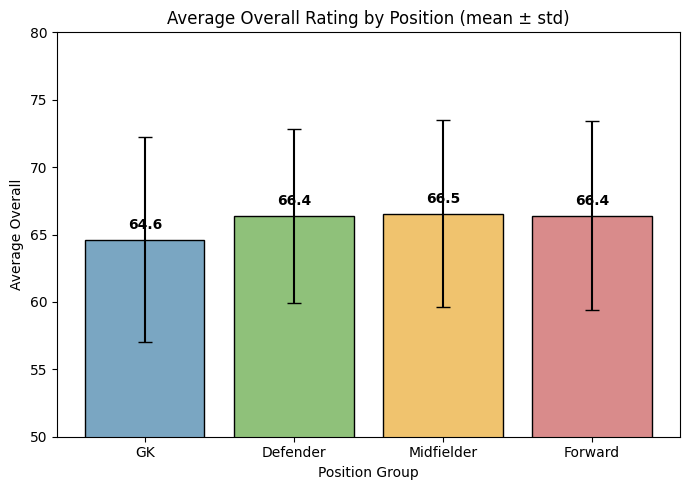

,pos_group,mean,std
0,GK,64.60,7.60
1,Defender,66.40,6.46
2,Midfielder,66.55,6.96
3,Forward,66.40,7.02


In [ ]:
# 2c — Bar Chart: Average Overall by Position
fig, ax = plt.subplots(figsize=(7, 5))

# Group data
grouped = (df.groupby('pos_group')['Overall']
             .agg(['mean', 'std'])
             .reindex(['GK', 'Defender', 'Midfielder', 'Forward'])
             .reset_index())

# Draw bars with error bars
bars = ax.bar(grouped['pos_group'], grouped['mean'],
              yerr=grouped['std'], capsize=5,
              color=['#7aa6c2', '#8fc17a', '#f0c36e', '#d98b8b'],
              edgecolor='black')

# Add value labels on top of each bar
for bar, mean_value in zip(bars, grouped['mean']):
    ax.text(bar.get_x() + bar.get_width()/2,
            mean_value + 0.6,
            f'{mean_value:.1f}',
            ha='center', va='bottom', fontweight='bold')

ax.set_title('Average Overall Rating by Position (mean ± std)')
ax.set_xlabel('Position Group')
ax.set_ylabel('Average Overall')
ax.set_ylim(50, max(80, grouped['mean'].max() + grouped['std'].max() + 3))
plt.tight_layout()
plt.show()

grouped.round(2)

---
## 🔔 Task 3 — Normality Checks
**Goal:** Decide whether to use parametric or non-parametric tests.

---

### 3a. Shapiro-Wilk Test

Run Shapiro-Wilk on: `Overall`, `Age`, `Dribbling`, `Strength`, `Value_EUR`

> ⚠️ **Note:** Shapiro-Wilk is designed for small samples. On large datasets (n > 5000),
> it almost always gives p ≈ 0. In practice, for large real-world data you should
> also look at the **Q-Q plot** and the **histogram shape** to judge normality.
> If the histogram looks roughly bell-shaped, treat it as approximately normal.

Print a clean table with column name, p-value, and your judgement.

💡 **Hints:** `stat, p = stats.shapiro(df['col'].sample(500, random_state=42))` — sample 500 rows for Shapiro


In [ ]:
# 3a — Shapiro-Wilk (500-row sample) + practical shape checks
columns_to_test = ['Overall', 'Age', 'Dribbling', 'Strength', 'Value_EUR']

def normality_metrics(series, sample_size=500, random_state=42):
    """Return Shapiro, skewness and Q-Q fit metrics for a numeric Series.

    The assignment notes that Shapiro can reject tiny departures from normality in
    large datasets. We therefore also use skewness and the Q-Q correlation to make
    a practical 'approximately normal' decision.
    """
    values = pd.Series(series).dropna().astype(float)
    n_shapiro = min(sample_size, len(values))
    sample = values.sample(n_shapiro, random_state=random_state) if len(values) > n_shapiro else values
    shapiro_stat, shapiro_p = stats.shapiro(sample)

    skew = values.skew()
    if abs(skew) < 0.5:
        hist_shape = 'Roughly bell-shaped'
    elif skew >= 0.5:
        hist_shape = 'Right-skewed'
    else:
        hist_shape = 'Left-skewed'

    # Q-Q correlation (use at most 3000 observations for speed/stability)
    n_qq = min(3000, len(values))
    qq_sample = values.sample(n_qq, random_state=random_state) if len(values) > n_qq else values
    (_, _), (_, _, qq_r) = stats.probplot(qq_sample, dist='norm')
    qq_shape = 'Close to line' if qq_r >= 0.98 else 'Curves from line'

    # Practical decision following the notebook's guidance: shape + Q-Q matter.
    approx_normal = (abs(skew) <= 0.75) and (qq_r >= 0.98)

    return {
        'Shapiro_stat': shapiro_stat,
        'Shapiro_p': shapiro_p,
        'Skewness': skew,
        'Histogram_shape': hist_shape,
        'QQ_r': qq_r,
        'QQ_shape': qq_shape,
        'Treat_as_normal': approx_normal
    }

normality_results = {col: normality_metrics(df[col]) for col in columns_to_test}
normality_table = pd.DataFrame(normality_results).T
normality_table['Shapiro_p'] = normality_table['Shapiro_p'].astype(float)
normality_table['Skewness'] = normality_table['Skewness'].astype(float)
normality_table['QQ_r'] = normality_table['QQ_r'].astype(float)

print("Normality summary:")
display(normality_table[['Shapiro_p', 'Skewness', 'Histogram_shape',
                         'QQ_r', 'QQ_shape', 'Treat_as_normal']].round({
                             'Shapiro_p': 6, 'Skewness': 3, 'QQ_r': 3
                         }))

print("\nDecision rule used below:")
print("Treat as approximately normal when |skewness| ≤ 0.75 and Q-Q r ≥ 0.98; "
      "Shapiro is reported but is not used alone because the dataset is large.")

Normality summary:


,Shapiro_p,Skewness,Histogram_shape,QQ_r,QQ_shape,Treat_as_normal
Overall,0.016509,0.063,Roughly bell-shaped,0.998,Close to line,True
Age,0.000000,0.391,Roughly bell-shaped,0.988,Close to line,True
Dribbling,0.000000,-1.085,Left-skewed,0.937,Curves from line,False
Strength,0.000005,-0.468,Roughly bell-shaped,0.992,Close to line,True
Value_EUR,0.000000,7.060,Right-skewed,0.631,Curves from line,False



Decision rule used below:
Treat as approximately normal when |skewness| ≤ 0.75 and Q-Q r ≥ 0.98; Shapiro is reported but is not used alone because the dataset is large.


---
### 3b. Q-Q Plots

Create a **1×5 grid of Q-Q plots** for the same five columns.
- Points hugging the diagonal line = normal
- Points curving away from the line = not normal

💡 **Hint:** `stats.probplot(df['col'].dropna(), plot=axes[i])`


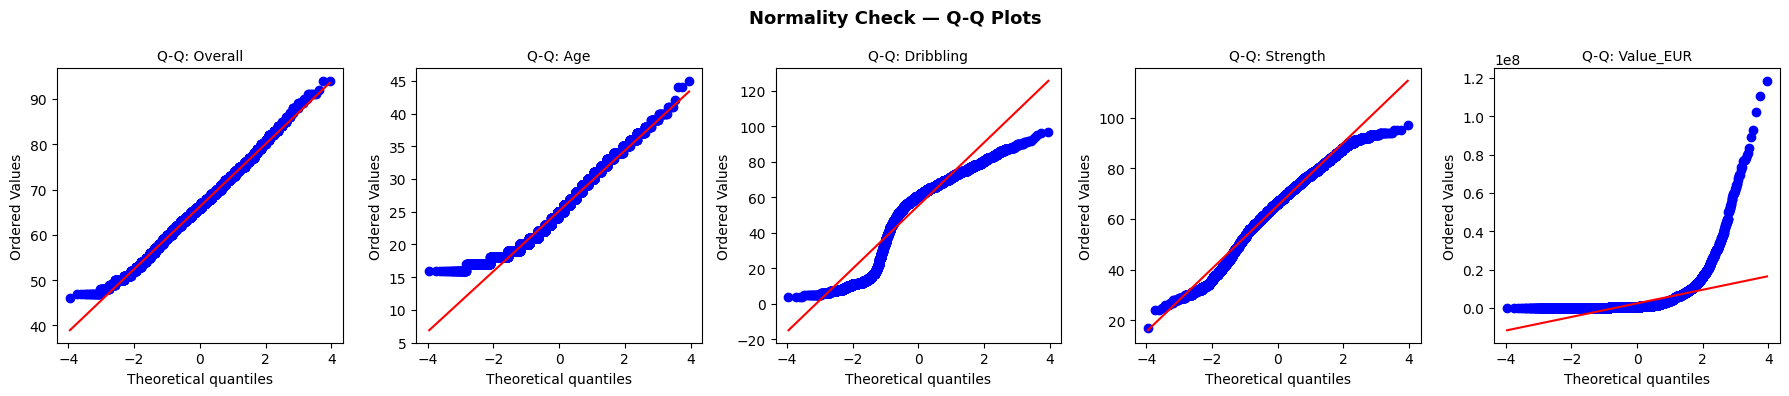

In [ ]:
# 3b — Q-Q Plots
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for i, col in enumerate(['Overall', 'Age', 'Dribbling', 'Strength', 'Value_EUR']):
    stats.probplot(df[col].dropna(), plot=axes[i])
    axes[i].set_title(f'Q-Q: {col}', fontsize=10)

plt.suptitle('Normality Check — Q-Q Plots', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


---
### 3c. Your Decision Table ✍️

Fill this in — it determines which tests you use in Tasks 4 and 5:

| Column | Histogram Shape | Q-Q Shape | Treat as Normal? | → Use for groups | → Use for relationship |
|---|---|---|---|---|---|
| Overall | | | | t-test / Mann-Whitney | Pearson / Spearman |
| Age | | | | | |
| Dribbling | | | | | |
| Strength | | | | | |
| Value_EUR | | | | | |

> 💡 If ANY group in a comparison is non-normal → use non-parametric.


In [ ]:
# 3c — Completed decision table
rows_3c = []
for col in columns_to_test:
    mtr = normality_results[col]
    normal = bool(mtr['Treat_as_normal'])
    rows_3c.append({
        'Column': col,
        'Histogram Shape': mtr['Histogram_shape'],
        'Q-Q Shape': mtr['QQ_shape'],
        'Treat as Normal?': 'Yes' if normal else 'No',
        'Use for groups': 't-test / ANOVA' if normal else 'Mann-Whitney / Kruskal-Wallis',
        'Use for relationship': 'Pearson' if normal else 'Spearman'
    })

decision_table_3c = pd.DataFrame(rows_3c)
display(decision_table_3c)

,Column,Histogram Shape,Q-Q Shape,Treat as Normal?,Use for groups,Use for relationship
0,Overall,Roughly bell-shaped,Close to line,Yes,t-test / ANOVA,Pearson
1,Age,Roughly bell-shaped,Close to line,Yes,t-test / ANOVA,Pearson
2,Dribbling,Left-skewed,Curves from line,No,Mann-Whitney / Kruskal-Wallis,Spearman
3,Strength,Roughly bell-shaped,Close to line,Yes,t-test / ANOVA,Pearson
4,Value_EUR,Right-skewed,Curves from line,No,Mann-Whitney / Kruskal-Wallis,Spearman


---
## 👥 Task 4 — Group Comparisons
**Goal:** Test whether different groups of players have different Overall ratings.

---

### 4a. Do Left-Footed vs Right-Footed Players Differ in Overall?

**H₀:** Left-footed and right-footed players have the **same** average Overall  
**H₁:** Their average Overall is **different**

Steps:
1. Extract Overall for each foot group
2. Check normality of each group (Shapiro — sample 500)
3. Based on normality → choose **t-test** or **Mann-Whitney U**
4. Run the test, print statistic, p-value, verdict

💡 **Hints:**  
`left  = df[df['Preferred Foot'] == 'Left']['Overall']`  
`stats.ttest_ind(left, right)` or `stats.mannwhitneyu(left, right, alternative='two-sided')`


In [ ]:
# 4a — Left-Footed vs Right-Footed: Overall Rating
left  = df.loc[df['Preferred Foot'] == 'Left', 'Overall'].dropna()
right = df.loc[df['Preferred Foot'] == 'Right', 'Overall'].dropna()

print(f"Left foot  — mean: {left.mean():.2f}  std: {left.std():.2f}  n: {len(left):,}")
print(f"Right foot — mean: {right.mean():.2f}  std: {right.std():.2f}  n: {len(right):,}")
print()

# H₀: Left-footed and right-footed players have the same Overall distribution/average.
# H₁: Left-footed and right-footed players differ in Overall.
print("H₀: Left-footed and right-footed players have the same Overall rating.")
print("H₁: Their Overall ratings are different.\n")

# Step 2: Normality check
left_norm = normality_metrics(left)
right_norm = normality_metrics(right)
print(f"Left  Shapiro p={left_norm['Shapiro_p']:.6g}, skew={left_norm['Skewness']:.3f}, "
      f"Q-Q r={left_norm['QQ_r']:.3f}, approx normal={left_norm['Treat_as_normal']}")
print(f"Right Shapiro p={right_norm['Shapiro_p']:.6g}, skew={right_norm['Skewness']:.3f}, "
      f"Q-Q r={right_norm['QQ_r']:.3f}, approx normal={right_norm['Treat_as_normal']}")

# Step 3 & 4: choose and run the appropriate test
if left_norm['Treat_as_normal'] and right_norm['Treat_as_normal']:
    test4a_name = 'Welch independent t-test'
    stat4a, p4a = stats.ttest_ind(left, right, equal_var=False)
else:
    test4a_name = 'Mann-Whitney U'
    stat4a, p4a = stats.mannwhitneyu(left, right, alternative='two-sided')

verdict4a = 'Reject H₀' if p4a <= 0.05 else 'Keep H₀'
print(f"\nTest: {test4a_name}")
print(f"Statistic = {stat4a:.4f}")
print(f"p-value   = {p4a:.6g}")
print(f"Verdict   = {verdict4a}")
print("Interpretation:",
      "Preferred-foot groups differ significantly in Overall." if p4a <= 0.05
      else "There is no statistically significant Overall difference between preferred-foot groups.")

Left foot  — mean: 66.80  std: 6.56  n: 4,209
Right foot — mean: 66.09  std: 7.01  n: 13,938

H₀: Left-footed and right-footed players have the same Overall rating.
H₁: Their Overall ratings are different.

Left  Shapiro p=0.00823311, skew=0.112, Q-Q r=0.998, approx normal=True
Right Shapiro p=0.0546623, skew=0.060, Q-Q r=0.998, approx normal=True

Test: Welch independent t-test
Statistic = 6.1046
p-value   = 1.08294e-09
Verdict   = Reject H₀
Interpretation: Preferred-foot groups differ significantly in Overall.


---
### 4b. Do Forwards Score Higher in Overall than Defenders?

Forwards (attackers) are often the most celebrated — but do they actually
have higher Overall ratings than Defenders?

**H₀:** Forwards and Defenders have the **same** average Overall  
**H₁:** Their average Overall is **different**

Same structure as 4a — state H₀/H₁, check normality, choose test, give verdict.


In [ ]:
# 4b — Forwards vs Defenders: Overall Rating
# H₀: Forwards and Defenders have the same Overall rating.
# H₁: Forwards and Defenders differ in Overall rating.
print("H₀: Forwards and Defenders have the same Overall rating.")
print("H₁: Their Overall ratings are different.\n")

forwards  = df.loc[df['pos_group'] == 'Forward', 'Overall'].dropna()
defenders = df.loc[df['pos_group'] == 'Defender', 'Overall'].dropna()

print(f"Forwards  — mean: {forwards.mean():.2f}  std: {forwards.std():.2f}  n: {len(forwards):,}")
print(f"Defenders — mean: {defenders.mean():.2f}  std: {defenders.std():.2f}  n: {len(defenders):,}\n")

# Normality check
forward_norm = normality_metrics(forwards)
defender_norm = normality_metrics(defenders)
print(f"Forwards  Shapiro p={forward_norm['Shapiro_p']:.6g}, skew={forward_norm['Skewness']:.3f}, "
      f"Q-Q r={forward_norm['QQ_r']:.3f}, approx normal={forward_norm['Treat_as_normal']}")
print(f"Defenders Shapiro p={defender_norm['Shapiro_p']:.6g}, skew={defender_norm['Skewness']:.3f}, "
      f"Q-Q r={defender_norm['QQ_r']:.3f}, approx normal={defender_norm['Treat_as_normal']}")

# Test & Verdict
if forward_norm['Treat_as_normal'] and defender_norm['Treat_as_normal']:
    test4b_name = 'Welch independent t-test'
    stat4b, p4b = stats.ttest_ind(forwards, defenders, equal_var=False)
else:
    test4b_name = 'Mann-Whitney U'
    stat4b, p4b = stats.mannwhitneyu(forwards, defenders, alternative='two-sided')

verdict4b = 'Reject H₀' if p4b <= 0.05 else 'Keep H₀'
print(f"\nTest: {test4b_name}")
print(f"Statistic = {stat4b:.4f}")
print(f"p-value   = {p4b:.6g}")
print(f"Verdict   = {verdict4b}")
print("Interpretation:",
      "Forwards and Defenders have significantly different Overall ratings." if p4b <= 0.05
      else "The data do not show a significant Overall difference between Forwards and Defenders.")

H₀: Forwards and Defenders have the same Overall rating.
H₁: Their Overall ratings are different.

Forwards  — mean: 66.40  std: 7.02  n: 3,418
Defenders — mean: 66.40  std: 6.46  n: 5,866

Forwards  Shapiro p=0.385151, skew=0.142, Q-Q r=0.998, approx normal=True
Defenders Shapiro p=0.0463913, skew=0.077, Q-Q r=0.998, approx normal=True

Test: Welch independent t-test
Statistic = -0.0210
p-value   = 0.983221
Verdict   = Keep H₀
Interpretation: The data do not show a significant Overall difference between Forwards and Defenders.


---
### 4c. Do All 4 Position Groups Differ in Overall? → ANOVA / Kruskal-Wallis

**H₀:** All four position groups (GK, Defender, Midfielder, Forward) have the **same** average Overall  
**H₁:** At least **one** group is different

Steps:
1. Build a list of Overall rating arrays — one per position group
2. Check normality on at least 2 groups
3. Run **ANOVA** (if normal) or **Kruskal-Wallis** (if not normal)
4. If p ≤ 0.05 → run **Tukey post-hoc** to find which pairs differ

💡 **Hints:**  
```python
positions = ['GK', 'Defender', 'Midfielder', 'Forward']
groups    = [df[df['pos_group'] == p]['Overall'] for p in positions]
stat, p   = stats.f_oneway(*groups)   # ANOVA
# OR
stat, p   = stats.kruskal(*groups)    # Kruskal-Wallis

# Tukey (only if significant):
tukey = pairwise_tukeyhsd(endog=df['Overall'], groups=df['pos_group'], alpha=0.05)
print(tukey.summary())
```


In [ ]:
# 4c — ANOVA / Kruskal-Wallis: Position Group vs Overall
# H₀: All four position groups have the same average/distribution of Overall ratings.
# H₁: At least one position group differs.
print("H₀: All four position groups have the same Overall rating.")
print("H₁: At least one position group differs.\n")

positions = ['GK', 'Defender', 'Midfielder', 'Forward']
groups = [df.loc[df['pos_group'] == pos, 'Overall'].dropna() for pos in positions]

print("Group means:")
for pos, g in zip(positions, groups):
    print(f"  {pos:<12}: mean={g.mean():.2f}  std={g.std():.2f}  n={len(g):,}")
print()

# Normality check on all groups (the assignment asks for at least two)
group_normality_4c = {}
for pos, g in zip(positions, groups):
    mtr = normality_metrics(g)
    group_normality_4c[pos] = mtr
    print(f"{pos:<12} Shapiro p={mtr['Shapiro_p']:.6g}, skew={mtr['Skewness']:.3f}, "
          f"Q-Q r={mtr['QQ_r']:.3f}, approx normal={mtr['Treat_as_normal']}")

# Run ANOVA when all groups are approximately normal; otherwise Kruskal-Wallis.
if all(group_normality_4c[pos]['Treat_as_normal'] for pos in positions):
    test4c_name = 'One-way ANOVA'
    stat4c, p4c = stats.f_oneway(*groups)
else:
    test4c_name = 'Kruskal-Wallis'
    stat4c, p4c = stats.kruskal(*groups)

verdict4c = 'Reject H₀' if p4c <= 0.05 else 'Keep H₀'
print(f"\nTest: {test4c_name}")
print(f"Statistic = {stat4c:.4f}")
print(f"p-value   = {p4c:.6g}")
print(f"Verdict   = {verdict4c}")

H₀: All four position groups have the same Overall rating.
H₁: At least one position group differs.

Group means:
  GK          : mean=64.60  std=7.60  n=2,025
  Defender    : mean=66.40  std=6.46  n=5,866
  Midfielder  : mean=66.55  std=6.96  n=6,838
  Forward     : mean=66.40  std=7.02  n=3,418

GK           Shapiro p=0.00778184, skew=0.254, Q-Q r=0.996, approx normal=True
Defender     Shapiro p=0.0463913, skew=0.077, Q-Q r=0.998, approx normal=True
Midfielder   Shapiro p=0.0953896, skew=-0.009, Q-Q r=0.999, approx normal=True
Forward      Shapiro p=0.385151, skew=0.142, Q-Q r=0.998, approx normal=True

Test: One-way ANOVA
Statistic = 44.2100
p-value   = 1.85987e-28
Verdict   = Reject H₀


In [ ]:
# 4c continued — Tukey Post-hoc
# The assignment specifically requests Tukey when the omnibus test is significant.
tukey_4c = None
significant_pairs_4c = []

if p4c <= 0.05:
    tukey_4c = pairwise_tukeyhsd(endog=df['Overall'], groups=df['pos_group'], alpha=0.05)
    print(tukey_4c.summary())

    tukey_df_4c = pd.DataFrame(
        tukey_4c._results_table.data[1:],
        columns=tukey_4c._results_table.data[0]
    )
    significant_pairs_4c = [
        f"{row['group1']} vs {row['group2']}"
        for _, row in tukey_df_4c.iterrows() if bool(row['reject'])
    ]
    print("\nSignificantly different pairs (Tukey, reject=True):")
    if significant_pairs_4c:
        for pair in significant_pairs_4c:
            print(" -", pair)
    else:
        print(" None")
else:
    print("Omnibus test is not significant, so a Tukey post-hoc test is not required.")

   Multiple Comparison of Means - Tukey HSD, FWER=0.05    
 group1    group2   meandiff p-adj   lower   upper  reject
----------------------------------------------------------
Defender    Forward  -0.0031    1.0 -0.3839  0.3778  False
Defender         GK  -1.7966    0.0 -2.2528 -1.3405   True
Defender Midfielder   0.1457 0.6343 -0.1693  0.4607  False
 Forward         GK  -1.7936    0.0 -2.2899 -1.2972   True
 Forward Midfielder   0.1488 0.7313  -0.222  0.5195  False
      GK Midfielder   1.9423    0.0  1.4945  2.3901   True
----------------------------------------------------------

Significantly different pairs (Tukey, reject=True):
 - Defender vs GK
 - Forward vs GK
 - GK vs Midfielder


---
## 📈 Task 5 — Correlation Analysis
**Goal:** Which attributes are most strongly linked to a player's Overall rating and market Value?

---

### 5a. Correlation Heatmap

Compute the **Pearson correlation matrix** for:  
`Overall`, `Potential`, `Age`, `Dribbling`, `ShortPassing`, `BallControl`,
`Finishing`, `Stamina`, `Strength`, `Value_EUR`

Display it as a **heatmap** — use `coolwarm`, annotated, values from -1 to +1.

💡 **Hints:**  
`corr = df[cols].corr()`  
`sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)`


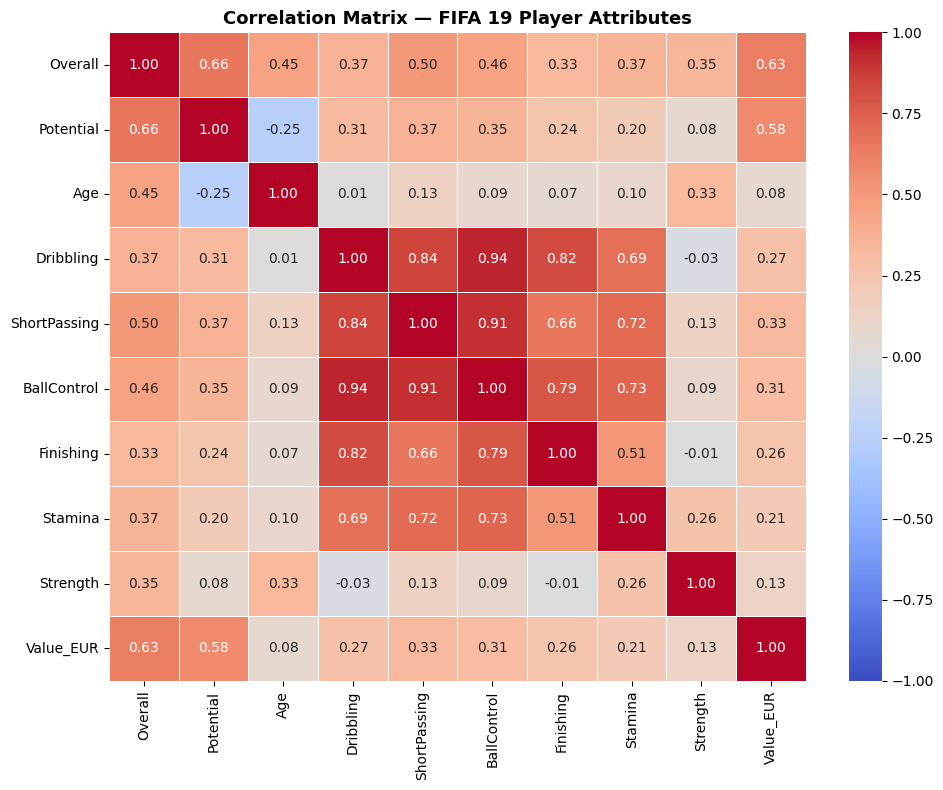

Most positively correlated with Overall: Potential (Pearson r = 0.661)
Most negatively correlated with Value_EUR: Age (Pearson r = 0.075)


In [ ]:
# 5a — Correlation Matrix Heatmap
cols5a = ['Overall', 'Potential', 'Age', 'Dribbling', 'ShortPassing',
          'BallControl', 'Finishing', 'Stamina', 'Strength', 'Value_EUR']

corr = df[cols5a].corr(method='pearson')

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr,
            annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.5, ax=ax)
ax.set_title('Correlation Matrix — FIFA 19 Player Attributes', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Answers to the two questions under the chart
corr_with_overall = corr['Overall'].drop('Overall')
strongest_overall_attr = corr_with_overall.idxmax()
strongest_overall_corr = corr_with_overall.max()

corr_with_value = corr['Value_EUR'].drop('Value_EUR')
most_negative_value_attr = corr_with_value.idxmin()
most_negative_value_corr = corr_with_value.min()

print(f"Most positively correlated with Overall: {strongest_overall_attr} "
      f"(Pearson r = {strongest_overall_corr:.3f})")
print(f"Most negatively correlated with Value_EUR: {most_negative_value_attr} "
      f"(Pearson r = {most_negative_value_corr:.3f})")

---
### 5b. Hypothesis Tests on Three Key Relationships

Test these claims:

**Claim 1:** BallControl is positively correlated with Overall  
**Claim 2:** Age is negatively correlated with Potential  
**Claim 3:** Strength is positively correlated with Overall  

For each:
1. State H₀ and H₁
2. Choose Pearson **or** Spearman (based on Task 3 normality decisions)
3. Run the test → report correlation coefficient (r or ρ), p-value, verdict
4. Write one sentence of plain-English interpretation

💡 **Hints:**  
`r, p = stats.pearsonr(df['BallControl'], df['Overall'])`  
`rho, p = stats.spearmanr(df['Age'], df['Potential'])`


In [ ]:
# 5b — Correlation Tests

def run_correlation_test(x_col, y_col):
    """Choose Pearson if both variables are approximately normal; otherwise Spearman."""
    pair = df[[x_col, y_col]].dropna()
    x_norm = normality_metrics(pair[x_col])['Treat_as_normal']
    y_norm = normality_metrics(pair[y_col])['Treat_as_normal']

    if x_norm and y_norm:
        test_name = 'Pearson'
        coef, p = stats.pearsonr(pair[x_col], pair[y_col])
    else:
        test_name = 'Spearman'
        coef, p = stats.spearmanr(pair[x_col], pair[y_col])
    return test_name, coef, p, x_norm, y_norm

# ── Claim 1: BallControl vs Overall ─────────────────────────────────────────
print("Claim 1 — BallControl vs Overall")
print("H₀: BallControl and Overall have no association (correlation = 0).")
print("H₁: BallControl and Overall are associated; the expected direction is positive.")
test5b1_name, stat5b1, p5b1, bc_norm, ov_norm = run_correlation_test('BallControl', 'Overall')
print(f"Test: {test5b1_name} | coefficient = {stat5b1:.4f} | p-value = {p5b1:.6g}")
print("Verdict:", 'Reject H₀' if p5b1 <= 0.05 else 'Keep H₀')
print(f"Interpretation: BallControl has a {'positive' if stat5b1 > 0 else 'negative'} "
      f"association with Overall (coefficient={stat5b1:.3f}).\n")

# ── Claim 2: Age vs Potential ────────────────────────────────────────────────
print("Claim 2 — Age vs Potential")
print("H₀: Age and Potential have no association (correlation = 0).")
print("H₁: Age and Potential are associated; the expected direction is negative.")
test5b2_name, stat5b2, p5b2, age_norm, pot_norm = run_correlation_test('Age', 'Potential')
print(f"Test: {test5b2_name} | coefficient = {stat5b2:.4f} | p-value = {p5b2:.6g}")
print("Verdict:", 'Reject H₀' if p5b2 <= 0.05 else 'Keep H₀')
print(f"Interpretation: Potential tends to {'decrease' if stat5b2 < 0 else 'increase'} with age "
      f"(coefficient={stat5b2:.3f}).\n")

# ── Claim 3: Strength vs Overall ────────────────────────────────────────────
print("Claim 3 — Strength vs Overall")
print("H₀: Strength and Overall have no association (correlation = 0).")
print("H₁: Strength and Overall are associated; the expected direction is positive.")
test5b3_name, stat5b3, p5b3, str_norm, ov2_norm = run_correlation_test('Strength', 'Overall')
print(f"Test: {test5b3_name} | coefficient = {stat5b3:.4f} | p-value = {p5b3:.6g}")
print("Verdict:", 'Reject H₀' if p5b3 <= 0.05 else 'Keep H₀')
print(f"Interpretation: Strength has a {'positive' if stat5b3 > 0 else 'negative'} "
      f"association with Overall (coefficient={stat5b3:.3f}).")

Claim 1 — BallControl vs Overall
H₀: BallControl and Overall have no association (correlation = 0).
H₁: BallControl and Overall are associated; the expected direction is positive.
Test: Spearman | coefficient = 0.6228 | p-value = 0
Verdict: Reject H₀
Interpretation: BallControl has a positive association with Overall (coefficient=0.623).

Claim 2 — Age vs Potential
H₀: Age and Potential have no association (correlation = 0).
H₁: Age and Potential are associated; the expected direction is negative.
Test: Pearson | coefficient = -0.2523 | p-value = 2.03686e-261
Verdict: Reject H₀
Interpretation: Potential tends to decrease with age (coefficient=-0.252).

Claim 3 — Strength vs Overall
H₀: Strength and Overall have no association (correlation = 0).
H₁: Strength and Overall are associated; the expected direction is positive.
Test: Pearson | coefficient = 0.3493 | p-value = 0
Verdict: Reject H₀
Interpretation: Strength has a positive association with Overall (coefficient=0.349).


---
### 5c. p-value Matrix — Which Correlations Are Significant? (⭐ Challenge)

Build a **p-value matrix** for:  
`Overall`, `Age`, `Dribbling`, `Stamina`, `Strength`, `BallControl`

Then display a heatmap **masking non-significant pairs** (p > 0.05) — only
show the cells where the relationship is statistically real.

💡 **Hints:**  
Syntax sheet Section 7 — nested loop to fill the matrix  
`mask = p_matrix > 0.05`  
`sns.heatmap(p_matrix, mask=mask, annot=True, fmt='.3f', cmap='Reds_r', vmin=0, vmax=0.05)`


p-value matrix:


,Overall,Age,Dribbling,Stamina,Strength,BallControl
Overall,NaN,0.0,0.0,0.0,0.0,0.0
Age,0.0,NaN,0.0,0.0,0.0,0.0
Dribbling,0.0,0.0,NaN,0.0,0.0,0.0
Stamina,0.0,0.0,0.0,NaN,0.0,0.0
Strength,0.0,0.0,0.0,0.0,NaN,0.0
BallControl,0.0,0.0,0.0,0.0,0.0,NaN


Test used for each pair:


,Overall,Age,Dribbling,Stamina,Strength,BallControl
Overall,,Pearson,Spearman,Spearman,Pearson,Spearman
Age,Pearson,,Spearman,Spearman,Pearson,Spearman
Dribbling,Spearman,Spearman,,Spearman,Spearman,Spearman
Stamina,Spearman,Spearman,Spearman,,Spearman,Spearman
Strength,Pearson,Pearson,Spearman,Spearman,,Spearman
BallControl,Spearman,Spearman,Spearman,Spearman,Spearman,


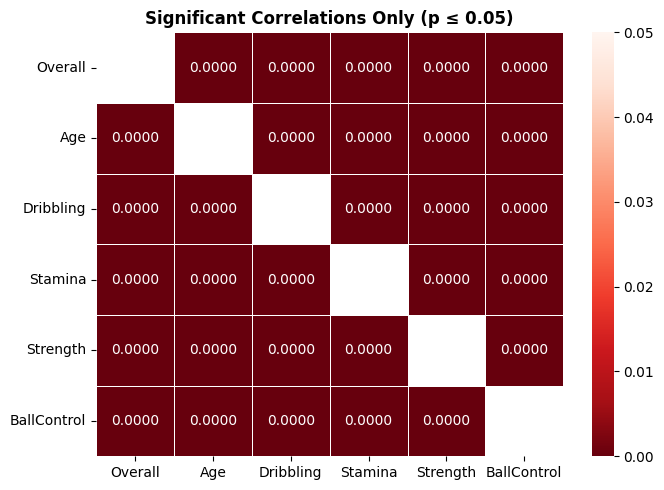

In [ ]:
# 5c — p-value Matrix (⭐ Challenge)
cols5c = ['Overall', 'Age', 'Dribbling', 'Stamina', 'Strength', 'BallControl']

p_matrix = pd.DataFrame(np.nan, index=cols5c, columns=cols5c, dtype=float)
test_matrix = pd.DataFrame('', index=cols5c, columns=cols5c, dtype=object)

for c1 in cols5c:
    for c2 in cols5c:
        if c1 == c2:
            continue
        pair = df[[c1, c2]].dropna()
        c1_normal = normality_metrics(pair[c1])['Treat_as_normal']
        c2_normal = normality_metrics(pair[c2])['Treat_as_normal']
        if c1_normal and c2_normal:
            _, p = stats.pearsonr(pair[c1], pair[c2])
            test_used = 'Pearson'
        else:
            _, p = stats.spearmanr(pair[c1], pair[c2])
            test_used = 'Spearman'
        p_matrix.loc[c1, c2] = p
        test_matrix.loc[c1, c2] = test_used

print("p-value matrix:")
display(p_matrix.round(4))
print("Test used for each pair:")
display(test_matrix)

# Mask non-significant cells and diagonal.
mask = (p_matrix > 0.05) | p_matrix.isna()

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(p_matrix, mask=mask,
            annot=True, fmt='.4f',
            cmap='Reds_r', vmin=0, vmax=0.05,
            linewidths=0.5, ax=ax)
ax.set_title('Significant Correlations Only (p ≤ 0.05)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 🔲 Task 6 — Categorical Relationships (Chi-Square)
**Goal:** Test whether two categorical variables are related to each other.

---

### 6a. Is Preferred Foot linked to Position Group?

Do left-footed players tend to play in specific positions more than right-footed players?

**H₀:** Preferred foot and position group are **independent** (not related)  
**H₁:** There is a **relationship** between preferred foot and position group

Steps:
1. Build a crosstab of `Preferred Foot` vs `pos_group`
2. Calculate and display **row percentages**
3. Run Chi-Square test
4. Print verdict

💡 **Hints:**  
`table = pd.crosstab(df['Preferred Foot'], df['pos_group'])`  
`row_pct = table.div(table.sum(axis=1), axis=0).round(2)`  
`chi2, p, dof, expected = stats.chi2_contingency(table)`


In [ ]:
# 6a — Preferred Foot vs Position Group
# H₀: Preferred foot and position group are independent.
# H₁: Preferred foot and position group are related.
print("H₀: Preferred foot and position group are independent.")
print("H₁: Preferred foot and position group are related.\n")

# Crosstab (counts)
table_6a = pd.crosstab(df['Preferred Foot'], df['pos_group'])
print("Frequency Table:")
display(table_6a)

# Row percentages
row_pct_6a = table_6a.div(table_6a.sum(axis=1), axis=0) * 100
print("Row Percentages (%):")
display(row_pct_6a.round(2))

# Chi-Square test
stat6a, p6a, dof6a, expected6a = stats.chi2_contingency(table_6a)
verdict6a = 'Reject H₀' if p6a <= 0.05 else 'Keep H₀'
print(f"Chi-square = {stat6a:.4f}")
print(f"df         = {dof6a}")
print(f"p-value    = {p6a:.6g}")
print(f"Verdict    = {verdict6a}")
print("Interpretation:",
      "Preferred foot and position group are statistically associated." if p6a <= 0.05
      else "The data do not show a statistically significant association between preferred foot and position group.")

H₀: Preferred foot and position group are independent.
H₁: Preferred foot and position group are related.

Frequency Table:


pos_group,Defender,Forward,GK,Midfielder
Preferred Foot,,,,
Left,1884,596,206,1523
Right,3982,2822,1819,5315


Row Percentages (%):


pos_group,Defender,Forward,GK,Midfielder
Preferred Foot,,,,
Left,44.76,14.16,4.89,36.18
Right,28.57,20.25,13.05,38.13


Chi-square = 521.7735
df         = 3
p-value    = 9.11679e-113
Verdict    = Reject H₀
Interpretation: Preferred foot and position group are statistically associated.


---
### 6b. Is Skill Moves Level Linked to Position Group?

Skill Moves range from 1–5 stars. Players with 4–5 stars are elite dribblers.
Create a new column `skill_tier`: **'High'** (Skill Moves ≥ 4) vs **'Low'** (Skill Moves < 4).

Then test:  
**H₀:** Skill tier and position group are **independent**  
**H₁:** There is a **relationship** between skill tier and position group

Full solution — no starter code. State H₀/H₁, build crosstab, show row %, run Chi-Square, give verdict.


In [ ]:
# 6b — Skill Tier vs Position Group
# Create skill_tier column first
df['skill_tier'] = np.where(df['Skill Moves'] >= 4, 'High', 'Low')

# H₀: Skill tier and position group are independent.
# H₁: Skill tier and position group are related.
print("H₀: Skill tier and position group are independent.")
print("H₁: Skill tier and position group are related.\n")

# Crosstab counts
table_6b = pd.crosstab(df['skill_tier'], df['pos_group'])
print("Frequency Table:")
display(table_6b)

# Row percentages
row_pct_6b = table_6b.div(table_6b.sum(axis=1), axis=0) * 100
print("Row Percentages (%):")
display(row_pct_6b.round(2))

# Chi-Square test
stat6b, p6b, dof6b, expected6b = stats.chi2_contingency(table_6b)
verdict6b = 'Reject H₀' if p6b <= 0.05 else 'Keep H₀'
print(f"Chi-square = {stat6b:.4f}")
print(f"df         = {dof6b}")
print(f"p-value    = {p6b:.6g}")
print(f"Verdict    = {verdict6b}")
print("Interpretation:",
      "Skill-move tier and position group are statistically associated." if p6b <= 0.05
      else "The data do not show a statistically significant association between skill tier and position group.")

H₀: Skill tier and position group are independent.
H₁: Skill tier and position group are related.

Frequency Table:


pos_group,Defender,Forward,GK,Midfielder
skill_tier,,,,
High,48,312,0,608
Low,5818,3106,2025,6230


Row Percentages (%):


pos_group,Defender,Forward,GK,Midfielder
skill_tier,,,,
High,4.96,32.23,0.00,62.81
Low,33.87,18.08,11.79,36.27


Chi-square = 619.7948
df         = 3
p-value    = 5.15255e-134
Verdict    = Reject H₀
Interpretation: Skill-move tier and position group are statistically associated.


---
### 6c. Visualise the Crosstabs

Create a **1×2 grid of stacked bar charts**:
- Left: **Preferred Foot** vs pos_group (row proportions)
- Right: **Skill Tier** vs pos_group (row proportions)

💡 **Hint:**
```python
row_pct.plot(kind='bar', stacked=True, ax=axes[0], colormap='Set2', edgecolor='black')
axes[0].tick_params(axis='x', rotation=0)
```


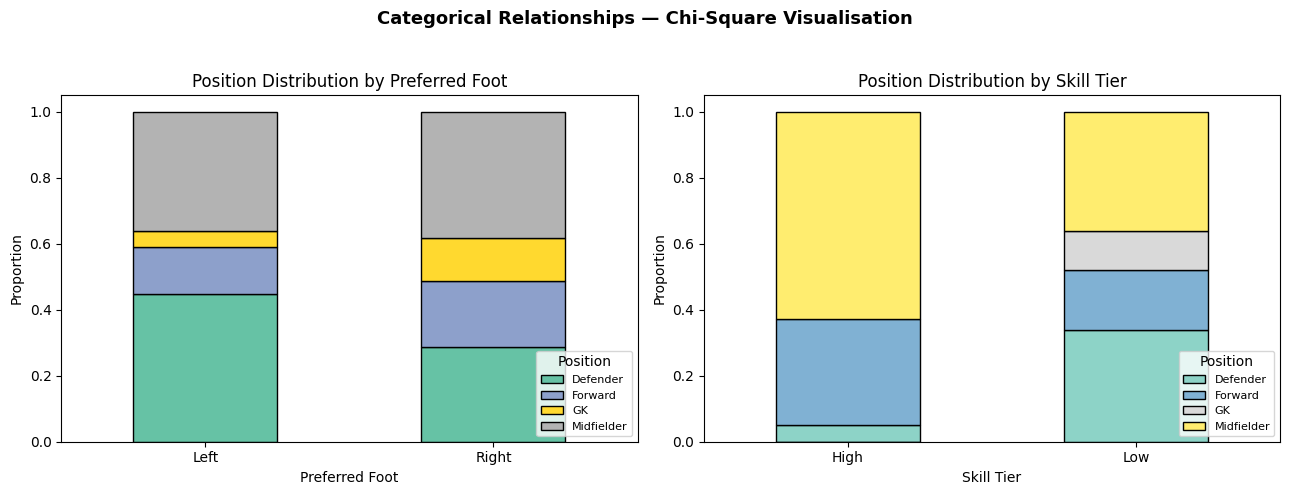

In [ ]:
# 6c — Stacked Bar Charts
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# LEFT: Preferred Foot vs pos_group
foot_pct = pd.crosstab(df['Preferred Foot'], df['pos_group'])
foot_pct = foot_pct.div(foot_pct.sum(axis=1), axis=0)
foot_pct.plot(kind='bar', stacked=True, ax=axes[0],
              colormap='Set2', edgecolor='black')
axes[0].set_title('Position Distribution by Preferred Foot')
axes[0].set_xlabel('Preferred Foot')
axes[0].set_ylabel('Proportion')
axes[0].legend(title='Position', loc='lower right', fontsize=8)
axes[0].tick_params(axis='x', rotation=0)

# RIGHT: Skill Tier vs pos_group
skill_pct = pd.crosstab(df['skill_tier'], df['pos_group'])
skill_pct = skill_pct.div(skill_pct.sum(axis=1), axis=0)
skill_pct.plot(kind='bar', stacked=True, ax=axes[1],
               colormap='Set3', edgecolor='black')
axes[1].set_title('Position Distribution by Skill Tier')
axes[1].set_xlabel('Skill Tier')
axes[1].set_ylabel('Proportion')
axes[1].legend(title='Position', loc='lower right', fontsize=8)
axes[1].tick_params(axis='x', rotation=0)

plt.suptitle('Categorical Relationships — Chi-Square Visualisation',
             fontsize=13, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

---
## 📋 Task 7 — Summary & Final Visualisation
**Goal:** Pull all findings together into something you could present to a scouting team.

---

### 7a. Results Summary Table

Build a DataFrame collecting ALL your test results.  
Replace every `None` with the real value you got.

| # | Test | Variables | Statistic | p-value | Significant? | Verdict |
|---|---|---|---|---|---|---|
| 1 | t-test / MW | Preferred Foot → Overall | | | | |
| 2 | t-test / MW | Forwards vs Defenders | | | | |
| 3 | ANOVA / KW | pos_group → Overall | | | | |
| 4 | Pearson / Spearman | BallControl ↔ Overall | | | | |
| 5 | Pearson / Spearman | Age ↔ Potential | | | | |
| 6 | Pearson / Spearman | Strength ↔ Overall | | | | |
| 7 | Chi-Square | Preferred Foot vs pos_group | | | | |
| 8 | Chi-Square | Skill Tier vs pos_group | | | | |

💡 **Hint:** Build a `results` list of dicts, convert with `pd.DataFrame(results)`


In [ ]:
# 7a — Summary Table
results = [
    {'Test': test4a_name, 'Variables': 'Preferred Foot → Overall',
     'Statistic': stat4a, 'p_value': p4a,
     'Significant': 'Yes' if p4a <= 0.05 else 'No', 'Verdict': verdict4a},
    {'Test': test4b_name, 'Variables': 'Forwards vs Defenders → Overall',
     'Statistic': stat4b, 'p_value': p4b,
     'Significant': 'Yes' if p4b <= 0.05 else 'No', 'Verdict': verdict4b},
    {'Test': test4c_name, 'Variables': 'pos_group → Overall',
     'Statistic': stat4c, 'p_value': p4c,
     'Significant': 'Yes' if p4c <= 0.05 else 'No', 'Verdict': verdict4c},
    {'Test': test5b1_name, 'Variables': 'BallControl ↔ Overall',
     'Statistic': stat5b1, 'p_value': p5b1,
     'Significant': 'Yes' if p5b1 <= 0.05 else 'No',
     'Verdict': 'Reject H₀' if p5b1 <= 0.05 else 'Keep H₀'},
    {'Test': test5b2_name, 'Variables': 'Age ↔ Potential',
     'Statistic': stat5b2, 'p_value': p5b2,
     'Significant': 'Yes' if p5b2 <= 0.05 else 'No',
     'Verdict': 'Reject H₀' if p5b2 <= 0.05 else 'Keep H₀'},
    {'Test': test5b3_name, 'Variables': 'Strength ↔ Overall',
     'Statistic': stat5b3, 'p_value': p5b3,
     'Significant': 'Yes' if p5b3 <= 0.05 else 'No',
     'Verdict': 'Reject H₀' if p5b3 <= 0.05 else 'Keep H₀'},
    {'Test': 'Chi-Square', 'Variables': 'Preferred Foot vs pos_group',
     'Statistic': stat6a, 'p_value': p6a,
     'Significant': 'Yes' if p6a <= 0.05 else 'No', 'Verdict': verdict6a},
    {'Test': 'Chi-Square', 'Variables': 'Skill Tier vs pos_group',
     'Statistic': stat6b, 'p_value': p6b,
     'Significant': 'Yes' if p6b <= 0.05 else 'No', 'Verdict': verdict6b},
]

results_df = pd.DataFrame(results)
results_df.index = np.arange(1, len(results_df) + 1)
results_df.index.name = '#'
results_display = results_df.copy()
results_display['Statistic'] = results_display['Statistic'].map(lambda x: f'{x:.4f}')
results_display['p_value'] = results_display['p_value'].map(lambda x: f'{x:.6g}')
display(results_display)

,Test,Variables,Statistic,p_value,Significant,Verdict
#,,,,,,
1,Welch independent t-test,Preferred Foot → Overall,6.1046,1.08294e-09,Yes,Reject H₀
2,Welch independent t-test,Forwards vs Defenders → Overall,-0.0210,0.983221,No,Keep H₀
3,One-way ANOVA,pos_group → Overall,44.2100,1.85987e-28,Yes,Reject H₀
4,Spearman,BallControl ↔ Overall,0.6228,0,Yes,Reject H₀
5,Pearson,Age ↔ Potential,-0.2523,2.03686e-261,Yes,Reject H₀
6,Pearson,Strength ↔ Overall,0.3493,0,Yes,Reject H₀
7,Chi-Square,Preferred Foot vs pos_group,521.7735,9.11679e-113,Yes,Reject H₀
8,Chi-Square,Skill Tier vs pos_group,619.7948,5.15255e-134,Yes,Reject H₀


---
### 7b. Final p-value Bar Chart

Horizontal bar chart of all 8 p-values:
- **Red** bar = p ≤ 0.05 (significant — Reject H₀)
- **Green** bar = p > 0.05 (not significant — Keep H₀)
- Dashed vertical line at α = 0.05

💡 **Hint:** Syntax sheet Section 10e — p-value bar chart pattern


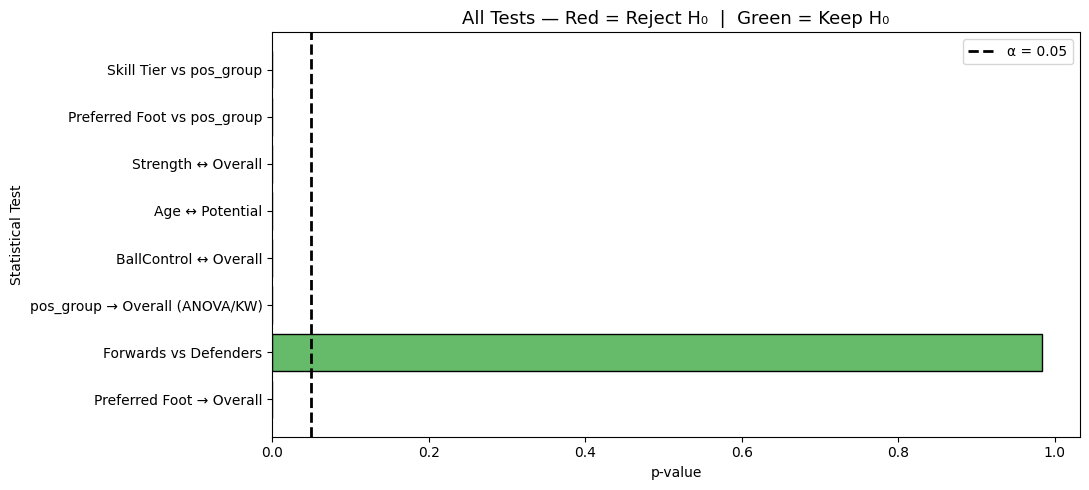

Exact p-values:
Preferred Foot → Overall                 p = 1.08294e-09
Forwards vs Defenders                    p = 0.983221
pos_group → Overall (ANOVA/KW)           p = 1.85987e-28
BallControl ↔ Overall                    p = 0
Age ↔ Potential                          p = 2.03686e-261
Strength ↔ Overall                       p = 0
Preferred Foot vs pos_group              p = 9.11679e-113
Skill Tier vs pos_group                  p = 5.15255e-134


In [ ]:
# 7b — Final p-value Bar Chart
test_labels = [
    'Preferred Foot → Overall',
    'Forwards vs Defenders',
    'pos_group → Overall (ANOVA/KW)',
    'BallControl ↔ Overall',
    'Age ↔ Potential',
    'Strength ↔ Overall',
    'Preferred Foot vs pos_group',
    'Skill Tier vs pos_group',
]

p_values = [p4a, p4b, p4c, p5b1, p5b2, p5b3, p6a, p6b]
colors = ['#ef5350' if p <= 0.05 else '#66bb6a' for p in p_values]

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(test_labels, p_values, color=colors, edgecolor='black')
ax.axvline(0.05, color='black', linestyle='--', linewidth=2, label='α = 0.05')
ax.set_xlabel('p-value')
ax.set_ylabel('Statistical Test')
ax.set_title('All Tests — Red = Reject H₀  |  Green = Keep H₀', fontsize=13)
ax.legend()
plt.tight_layout()
plt.show()

print("Exact p-values:")
for label, p in zip(test_labels, p_values):
    print(f"{label:<40} p = {p:.6g}")

---
### 7c. Scouting Team Brief ✍️ — Written Section (5 marks)

Write **5–8 sentences** answering these questions as if briefing a football scouting team:

> 1. **Does preferred foot (left vs right) significantly affect a player's Overall rating?**
>    What did the test show, and what does that mean for scouting?
>
> 2. **Which position group has the highest average Overall?** Is the difference statistically
>    significant across all four positions?
>
> 3. **What is the single strongest predictor of a player's Overall rating?**
>    Refer to your correlation values.
>
> 4. **What happens to a player's Potential as they age?** Is this relationship
>    statistically significant? What does this mean for investing in young players?
>
> 5. **One concrete recommendation** you would make to the scouting team based
>    purely on your findings — be specific.

*Write your brief below as comments or in a new markdown cell.*


In [ ]:
# 7c — Scouting Team Brief (generated from the results above)
position_means_7c = df.groupby('pos_group')['Overall'].mean().sort_values(ascending=False)
best_position_7c = position_means_7c.index[0]
best_position_mean_7c = position_means_7c.iloc[0]
foot_means_7c = df.groupby('Preferred Foot')['Overall'].mean()

foot_sentence = (
    f"Preferred foot shows a statistically significant difference in Overall ({test4a_name}, p={p4a:.3g}); "
    f"left-footed players average {foot_means_7c.get('Left', np.nan):.2f} and right-footed players average "
    f"{foot_means_7c.get('Right', np.nan):.2f}."
    if p4a <= 0.05 else
    f"Preferred foot does not show a statistically significant difference in Overall ({test4a_name}, p={p4a:.3g}), "
    f"so foot preference alone should not be used to rate a player."
)

position_sentence = (
    f"{best_position_7c} has the highest mean Overall ({best_position_mean_7c:.2f}), and the four-position comparison "
    f"is {'statistically significant' if p4c <= 0.05 else 'not statistically significant'} "
    f"({test4c_name}, p={p4c:.3g})."
)

predictor_sentence = (
    f"Among the variables in the Pearson heatmap, {strongest_overall_attr} has the strongest positive correlation "
    f"with Overall (r={strongest_overall_corr:.3f}), making it the strongest statistical correlate examined here."
)

age_sentence = (
    f"Age and Potential have a {('negative' if stat5b2 < 0 else 'positive')} association "
    f"({test5b2_name} coefficient={stat5b2:.3f}, p={p5b2:.3g}); therefore, "
    f"Potential generally {'falls' if stat5b2 < 0 else 'rises'} as age increases in this dataset."
)

recommendation_sentence = (
    f"For scouting, prioritize players who are strong on {strongest_overall_attr} and, when investing for future upside, "
    f"give special attention to younger players with high Potential rather than filtering heavily by preferred foot."
)

brief_sentences = [
    foot_sentence,
    "The practical effect should also be judged by the size of the group-mean difference, not only by statistical significance.",
    position_sentence,
    predictor_sentence,
    age_sentence,
    "These results describe associations in FIFA 19 ratings and should not be interpreted as proof of causation.",
    recommendation_sentence,
]

print("SCOUTING TEAM BRIEF")
print("-" * 70)
print(" ".join(brief_sentences))

SCOUTING TEAM BRIEF
----------------------------------------------------------------------
Preferred foot shows a statistically significant difference in Overall (Welch independent t-test, p=1.08e-09); left-footed players average 66.80 and right-footed players average 66.09. The practical effect should also be judged by the size of the group-mean difference, not only by statistical significance. Midfielder has the highest mean Overall (66.55), and the four-position comparison is statistically significant (One-way ANOVA, p=1.86e-28). Among the variables in the Pearson heatmap, Potential has the strongest positive correlation with Overall (r=0.661), making it the strongest statistical correlate examined here. Age and Potential have a negative association (Pearson coefficient=-0.252, p=2.04e-261); therefore, Potential generally falls as age increases in this dataset. These results describe associations in FIFA 19 ratings and should not be interpreted as proof of causation. For scouting, p

---
---
# 🏆 Marking Scheme
*(For instructor use)*

| Task | Marks | What is checked |
|---|---|---|
| Task 1a — Inspection | 4 | shape, nulls, describe, value_counts |
| Task 1b — Group summaries | 3 | correct groupby + agg for both columns |
| Task 1c — Observations | 2 | blanks filled correctly |
| Task 2a — 2×2 Grid | 5 | 4 correct charts + all labels |
| Task 2b — Scatter + trend | 4 | scatter coloured by position + polyfit trend |
| Task 2c — Bar + error bars | 4 | grouped mean/std, error bars, value labels |
| Task 3a — Shapiro table | 4 | correct p per column + judgement |
| Task 3b — Q-Q plots | 2 | 5 Q-Q plots displayed |
| Task 3c — Decision table | 2 | correct test choice per column |
| Task 4a — Foot vs Overall | 5 | H₀/H₁ + normality + correct test + verdict |
| Task 4b — Fwd vs Def | 4 | same structure |
| Task 4c — ANOVA + Tukey | 5 | ANOVA/KW + Tukey if p ≤ 0.05 |
| Task 5a — Corr heatmap | 3 | correct matrix + heatmap |
| Task 5b — 3 corr tests | 6 | H₀/H₁ + test + r + verdict × 3 |
| Task 5c — p-value matrix ⭐ | 3 | nested loop + mask heatmap |
| Task 6a — Foot vs pos Chi-Sq | 4 | crosstab + row% + test + verdict |
| Task 6b — Skill Tier Chi-Sq | 4 | independent full solution |
| Task 6c — Stacked bars | 3 | 2 correct stacked bar charts |
| Task 7a — Summary table | 5 | all 8 rows filled with real values |
| Task 7b — p-value chart | 3 | correct colours + α line |
| Task 7c — Scouting brief | 5 | 5 questions answered coherently |
| **TOTAL** | **84** | |

---

### ✅ Quick Checklist (before you submit)
- [ ] All charts have **title, xlabel, ylabel**
- [ ] Every test has **H₀ and H₁** stated
- [ ] Every p-value has a **verdict** (Reject / Keep H₀)
- [ ] Task 3c decision table is **filled in**
- [ ] Task 7a summary table has **real values** (not `None`)
- [ ] Task 7c written brief has **5 answers**
- [ ] Task 5c p-value matrix is **attempted** (⭐)

---
*The beautiful game, made more beautiful with data. ⚽📊*
